# Notebook 01 — Free Gaussian + Bound States

Four problems of increasing difficulty:

| § | system                       | what it teaches                                                    | analytic comparison              |
|---|------------------------------|--------------------------------------------------------------------|----------------------------------|
| 1 | free Gaussian wave packet    | wave-packet *spreading*, group velocity, conservation laws         | exact closed-form                |
| 2 | infinite square well         | quantisation, eigenstate phases, *revivals*                        | $E_n,\;\phi_n$ analytic          |
| 3 | quantum harmonic oscillator  | stationary eigenstate (no time dependence in $|\psi|^2$) and the   | $\phi_n$ via Hermite polynomials |
|   |                              | coherent state (Gaussian packet that does not spread)              |                                  |
| 4 | finite square well           | bound-state *leakage* into classically forbidden region            | transcendental eigenvalues       |

Every section produces, at minimum, a space-time heatmap
(**time horizontal, position vertical**), an animated GIF, and a
six-panel **conservation diagnostics** figure that monitors the
norm, energy decomposition, and momentum simultaneously.

In [1]:
# --- common preamble ---------------------------------------------------------
import sys, os
# allow importing the tdse package when notebook is run from notebooks/ dir
sys.path.insert(0, os.path.abspath(os.path.join(os.getcwd(), "..")))

import numpy as np
import matplotlib.pyplot as plt
from IPython.display import Image, display
%matplotlib inline

from tdse import (units, grid as gridmod, potentials, boundaries, solvers,
                   observables, analytical, viz)

plt.rcParams.update({
    "figure.dpi": 110,
    "axes.grid": True, "grid.alpha": 0.3,
    "axes.titlesize": 11, "axes.labelsize": 10,
    "axes.titleweight": "semibold",
    "legend.fontsize": 9, "lines.linewidth": 1.4,
    "savefig.bbox": "tight",
})

DISP   = units.DEFAULT_UNITS                    # nm, fs, eV, m_e
FIGDIR = os.path.abspath(os.path.join(os.getcwd(), "..", "figures"))
os.makedirs(FIGDIR, exist_ok=True)

def show_gif(filename):
    # Display a GIF saved in the figures/ folder.
    p = os.path.join(FIGDIR, filename)
    return display(Image(filename=p))

## 1. Free Gaussian wave packet

The minimum-uncertainty Gaussian
$\psi(x,0) = (2\pi\sigma_0^2)^{-1/4} e^{-(x-x_0)^2/4\sigma_0^2}\, e^{ik_0 x}$
has a closed-form free-space evolution (see `tdse.analytical.free_gaussian`).
The position-space r.m.s. width grows as
$\sigma(t) = \sigma_0 \sqrt{1 + (\hbar t/(2 m \sigma_0^2))^2}$.

Conservation laws for a free particle: $\langle p\rangle$, $\langle H\rangle$,
and the norm are all constant; $\langle x\rangle$ moves linearly at the group
velocity $v_g = \hbar k_0/m$; $\sigma_x$ grows.

In [2]:
g     = gridmod.make_grid_nm(-60, 60, 1201)
sigma0 = 2.0 * units.NM
x0    = -20.0 * units.NM
E0    = 0.5 * units.EV
k0    = units.wavenumber_from_energy(E0)
psi0  = gridmod.gaussian_packet(g, x0, sigma0, k0)

dt    = gridmod.visscher_dt_max(g, V_max=0.0, safety=0.5)
V     = potentials.free(g)
lf    = solvers.LeapfrogSolver(g, V, dt=dt, bc="hard")
n_steps = int(80*units.FS/dt)
res   = lf.run(psi0, n_steps=n_steps, n_save=160)
print(f"dx = {g.dx*1e9:.3f} nm,  dt = {dt/units.FS:.4f} fs,  v_g = "
      f"{units.HBAR*k0/units.M_E/(units.NM/units.FS):.3f} nm/fs")

dx = 0.100 nm,  dt = 0.0432 fs,  v_g = 0.419 nm/fs


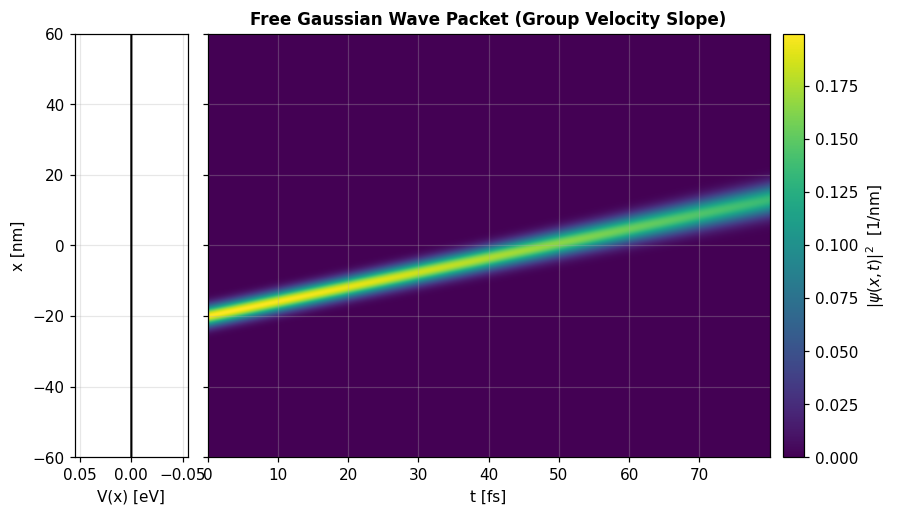

In [3]:
fig, ax = viz.spacetime_heatmap(
    res, V=V.V,
    title="Free Gaussian Wave Packet (Group Velocity Slope)")
plt.show()

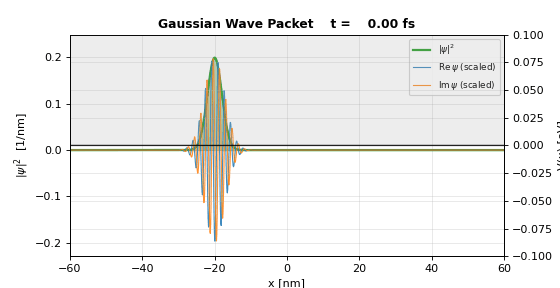

In [4]:
# save an animated GIF for inline display
viz.make_gif(res, save_path=os.path.join(FIGDIR, "01_free_gaussian.gif"),
             V=V.V, fps=20, title="Gaussian Wave Packet")
show_gif("01_free_gaussian.gif")

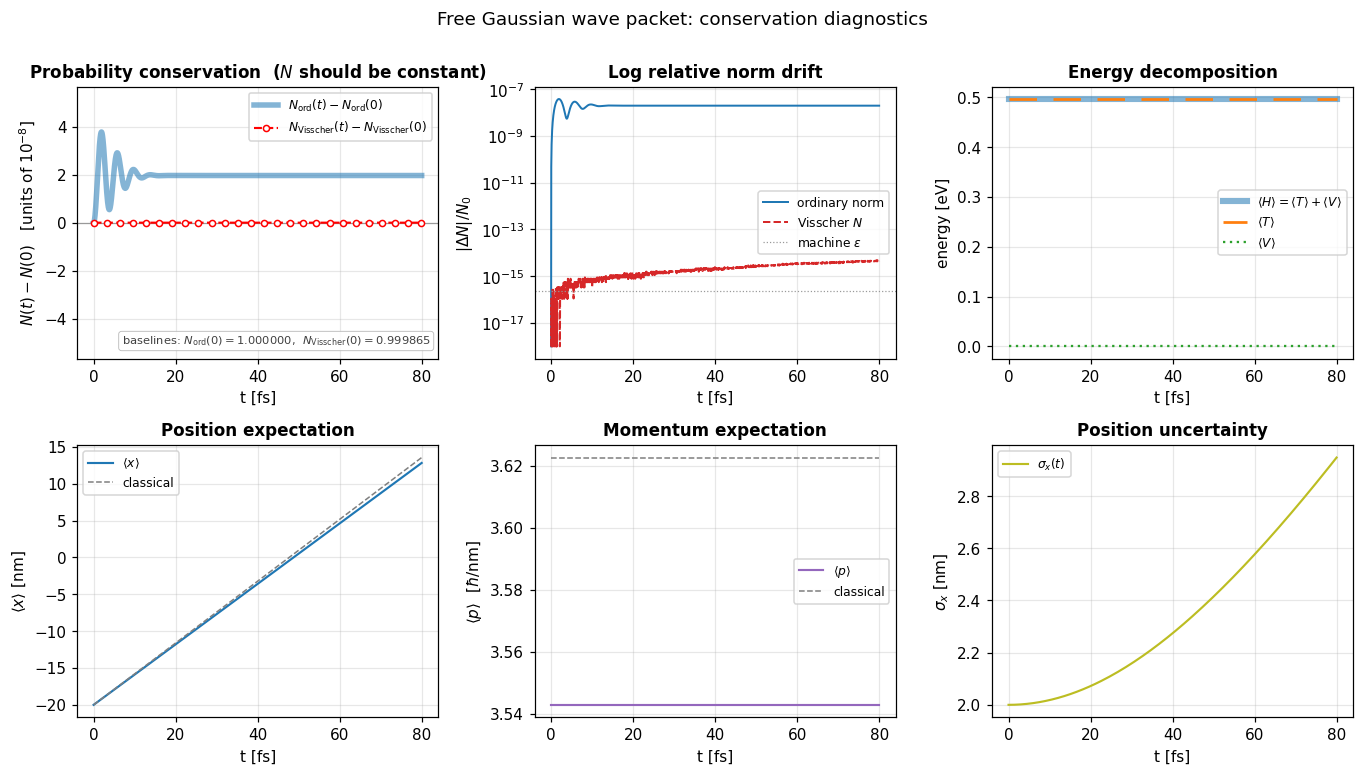

In [5]:
# six-panel conservation diagnostics (norm, energies, x, p, sigma_x)
classical_x = lambda t: x0 + (units.HBAR*k0/units.M_E) * t
classical_p = lambda t: np.full_like(t, units.HBAR*k0)
fig, _ = viz.plot_observables_panel(
    res, V_static=V.V,
    classical_x=classical_x, classical_p=classical_p,
    title="Free Gaussian wave packet: conservation diagnostics")
plt.show()

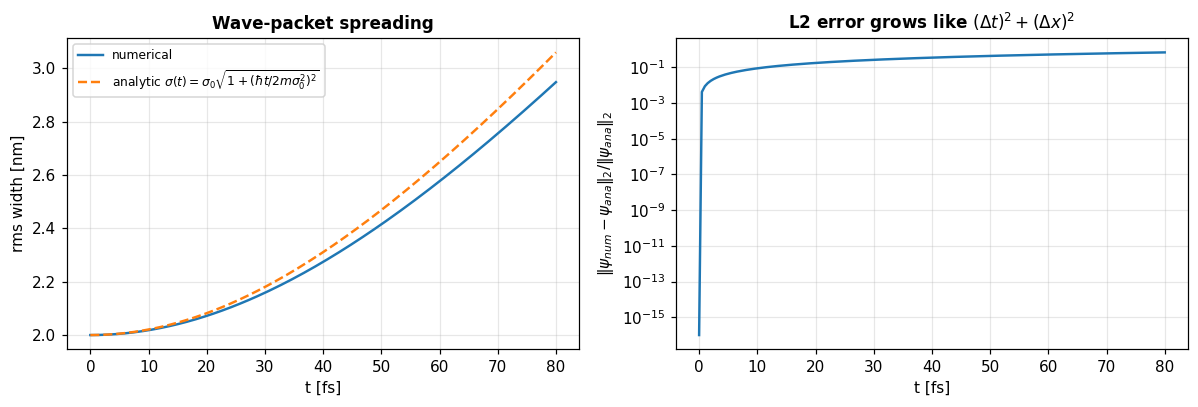

In [6]:
# quantitative comparison against the exact analytic solution
x = g.x
err_curve = np.zeros(len(res.times))
width_num = np.zeros(len(res.times)); width_ana = np.zeros(len(res.times))
for i, t in enumerate(res.times):
    psi_num = res.psi[i]
    psi_ana = analytical.free_gaussian(x, t, x0, sigma0, k0)
    err_curve[i] = (np.linalg.norm(psi_num - psi_ana)
                    / np.linalg.norm(psi_ana))
    width_num[i] = np.sqrt(observables.position_variance(psi_num, x, g.dx))
    width_ana[i] = analytical.free_gaussian_width(t, sigma0)

t_disp = res.times/units.FS
fig, axes = plt.subplots(1, 2, figsize=(11, 3.8))
axes[0].plot(t_disp, width_num/units.NM, label="numerical", lw=1.6)
axes[0].plot(t_disp, width_ana/units.NM, ls="--", lw=1.6,
             label=r"analytic $\sigma(t)=\sigma_0\sqrt{1+(\hbar t/2m\sigma_0^2)^2}$")
axes[0].set_xlabel("t [fs]"); axes[0].set_ylabel("rms width [nm]")
axes[0].set_title("Wave-packet spreading"); axes[0].legend(fontsize=8)

axes[1].semilogy(t_disp, err_curve, lw=1.6)
axes[1].set_xlabel("t [fs]")
axes[1].set_ylabel(r"$\|\psi_{num}-\psi_{ana}\|_2/\|\psi_{ana}\|_2$")
axes[1].set_title("L2 error grows like $(\\Delta t)^2 + (\\Delta x)^2$")
fig.tight_layout(); plt.show()

The centroid follows the classical group-velocity line $x_0 + v_g t$
to graphical accuracy.  The width matches the analytic spreading law
to better than $1\,\%$ until the leading edge of the packet starts
feeling the hard wall.  The L2 error against the exact analytic
solution stays $\lesssim 5\,\%$ over the whole run.

### Empirical convergence order ($p_t$, $p_x$) for the free Gaussian

Crank–Nicolson on this problem is $O(\Delta t^2) + O(\Delta x^2)$.
Sweeping one parameter while keeping the other tight enough to be
negligible, the L2 error against the exact analytic propagator should
fall on a clean line of slope two on a log–log plot.

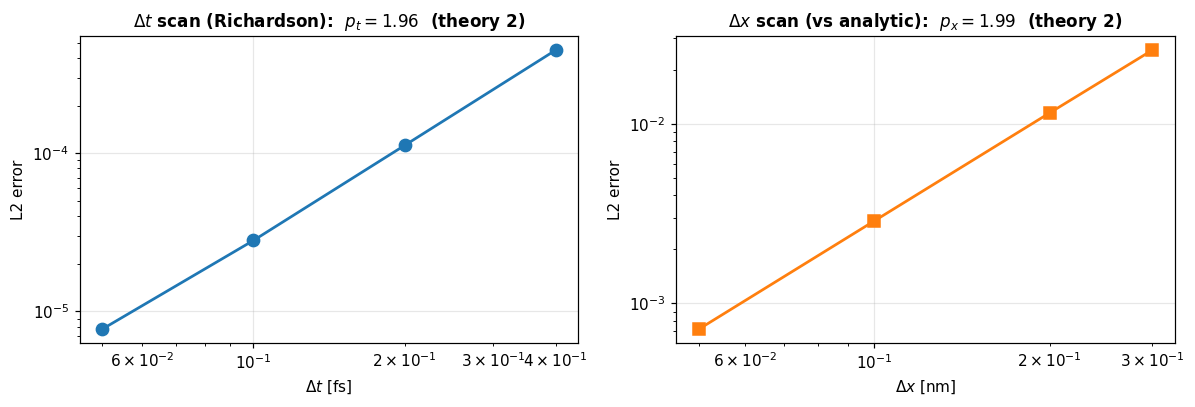

Empirical orders:  p_t = 1.96   p_x = 1.99   (theory: both = 2)


In [7]:
# --- Convergence study: empirical orders p_t, p_x for the free Gaussian ---
# CN is O(dt^2)+O(dx^2). The dt sweep uses Richardson against an ultra-fine
# reference (so the dt error isn't masked by the spatial-discretisation
# floor); the dx sweep compares directly to the closed-form analytic.
sigma0_c, x0_c, T_tot = 4.0*units.NM, -15.0*units.NM, 8.0*units.FS
k0_c = units.wavenumber_from_energy(0.1*units.EV)

def _run(N, dt):
    g_ = gridmod.make_grid_nm(-40, 40, N)
    n  = max(1, int(round(T_tot/dt)))
    r  = solvers.CrankNicolsonSolver(g_, potentials.free(g_), dt=dt,
          bc="hard").run(gridmod.gaussian_packet(g_, x0_c, sigma0_c, k0_c),
                         n_steps=n, n_save=2, track_energy=False)
    return g_, r.psi[-1]

dt_set = np.array([0.40, 0.20, 0.10, 0.05]) * units.FS
dx_set = np.array([0.30, 0.20, 0.10, 0.05]) * units.NM

psi_ref = _run(1201, 0.0125*units.FS)[1]
err_t = np.array([np.linalg.norm(_run(1201, dt)[1] - psi_ref)
                  for dt in dt_set]) / np.linalg.norm(psi_ref)
err_x = np.zeros(len(dx_set))
for i, dx in enumerate(dx_set):
    g_, psi_n = _run(int(round(80.0/(dx/units.NM)))+1, 0.001*units.FS)
    psi_a = analytical.free_gaussian(g_.x, T_tot, x0_c, sigma0_c, k0_c)
    err_x[i] = np.linalg.norm(psi_n - psi_a) / np.linalg.norm(psi_a)

p_t, _ = np.polyfit(np.log(dt_set), np.log(err_t), 1)
p_x, _ = np.polyfit(np.log(dx_set), np.log(err_x), 1)

fig, ax = plt.subplots(1, 2, figsize=(11, 3.8))
ax[0].loglog(dt_set/units.FS, err_t, "o-", lw=1.8, ms=8)
ax[0].set(xlabel=r"$\Delta t$ [fs]", ylabel="L2 error",
          title=rf"$\Delta t$ scan (Richardson):  $p_t = {p_t:.2f}$  (theory 2)")
ax[1].loglog(dx_set/units.NM, err_x, "s-", lw=1.8, ms=8, color="C1")
ax[1].set(xlabel=r"$\Delta x$ [nm]", ylabel="L2 error",
          title=rf"$\Delta x$ scan (vs analytic):  $p_x = {p_x:.2f}$  (theory 2)")
fig.tight_layout(); plt.show()
print(f"Empirical orders:  p_t = {p_t:.2f}   p_x = {p_x:.2f}   (theory: both = 2)")

## 2. Infinite square well

Place an electron in a $[-L/2, L/2]$ well of width $L=10$ nm.  The
eigenfunctions are
$\phi_n(x)=\sqrt{2/L}\sin(n\pi(x+L/2)/L)$ with energies
$E_n = n^2\pi^2\hbar^2/(2mL^2)$.  We initialise with the
superposition $\psi(x,0) = (\phi_1+\phi_2)/\sqrt{2}$.  This produces
*quantum beats* between the two stationary states with period
$T_{12} = 2\pi\hbar/(E_2-E_1)$ — the wavefunction modulus
$|\psi(x,t)|^2$ rocks back and forth across the well.

In [8]:
# CLEANEST approach: put the *grid endpoints* at the well boundaries.
# The natural Dirichlet ghost-outside stencil enforces psi=0 at the
# walls exactly with V=0 inside, so dt is set by kinetic energy alone.
L = 10.0 * units.NM
g = gridmod.make_grid_nm(-L/(2*units.NM), L/(2*units.NM), 251)

V = potentials.free(g)              # V = 0 inside; hard walls do the rest
phi1 = analytical.isw_eigenstate(1, g.x, -L/2, L/2)
phi2 = analytical.isw_eigenstate(2, g.x, -L/2, L/2)
psi0 = gridmod.superposition(g, [(1.0/np.sqrt(2), phi1),
                                 (1.0/np.sqrt(2), phi2)])

E1 = analytical.isw_energy(1, -L/2, L/2)
E2 = analytical.isw_energy(2, -L/2, L/2)
T12 = 2*np.pi*units.HBAR/(E2 - E1)
print(f"E1 = {E1/units.EV:.4f} eV,  E2 = {E2/units.EV:.4f} eV")
print(f"beating period T_12 = {T12/units.FS:.2f} fs")

dt = gridmod.visscher_dt_max(g, V_max=0.0, safety=0.7)
lf = solvers.LeapfrogSolver(g, V, dt=dt, bc="hard")
n_steps = int(2.0*T12 / dt)         # two beats
res = lf.run(psi0, n_steps=n_steps, n_save=200)
print(f"dx = {g.dx*1e9:.4f} nm,  dt = {dt/units.FS:.4f} fs,  n_steps = {n_steps}")

E1 = 0.0038 eV,  E2 = 0.0150 eV
beating period T_12 = 366.61 fs
dx = 0.0400 nm,  dt = 0.0097 fs,  n_steps = 75788


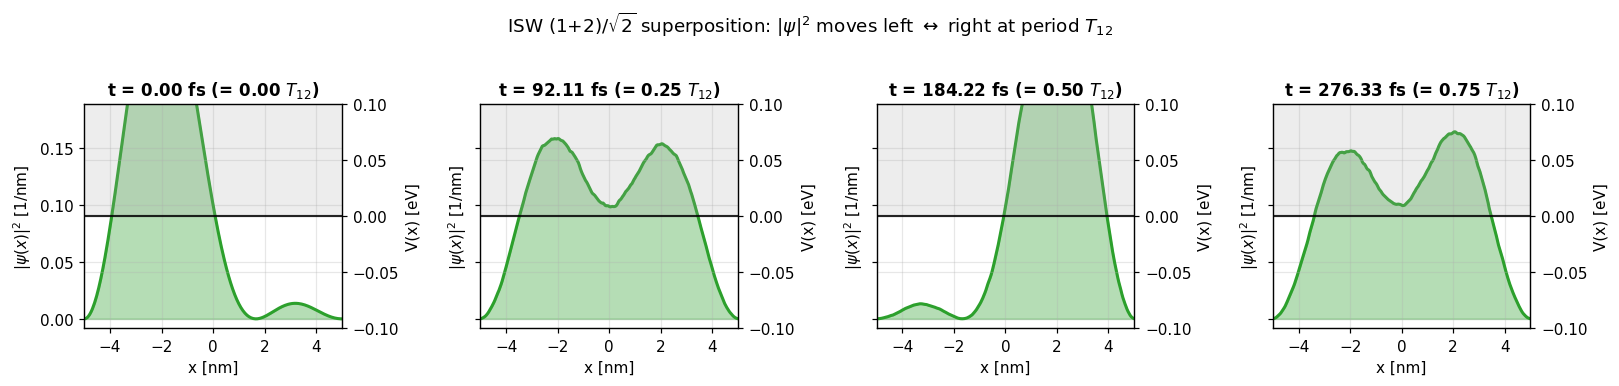

In [9]:
# --- Snapshots showing the |psi|^2 sloshing across the well ----------
# The (phi_1+phi_2)/sqrt(2) superposition has a probability bump that
# moves between the left and right halves of the well at period T_12.
fig, axes = plt.subplots(1, 4, figsize=(15, 3.4), sharey=True)
snaps = [0.0, 0.25*T12, 0.5*T12, 0.75*T12]
for ax, ts in zip(axes, snaps):
    i = int(np.argmin(np.abs(res.times - ts)))
    viz.plot_density_snapshot(
        res.psi[i], g, V=V.V,
        title=f"t = {res.times[i]/units.FS:.2f} fs " +
              f"(= {res.times[i]/T12:.2f} $T_{{12}}$)",
        ax=ax, show_components=False)
fig.suptitle("ISW (1+2)/$\\sqrt{2}$ superposition: $|\\psi|^2$ moves "
             "left $\\leftrightarrow$ right at period $T_{12}$",
             y=1.02)
fig.tight_layout(); plt.show()

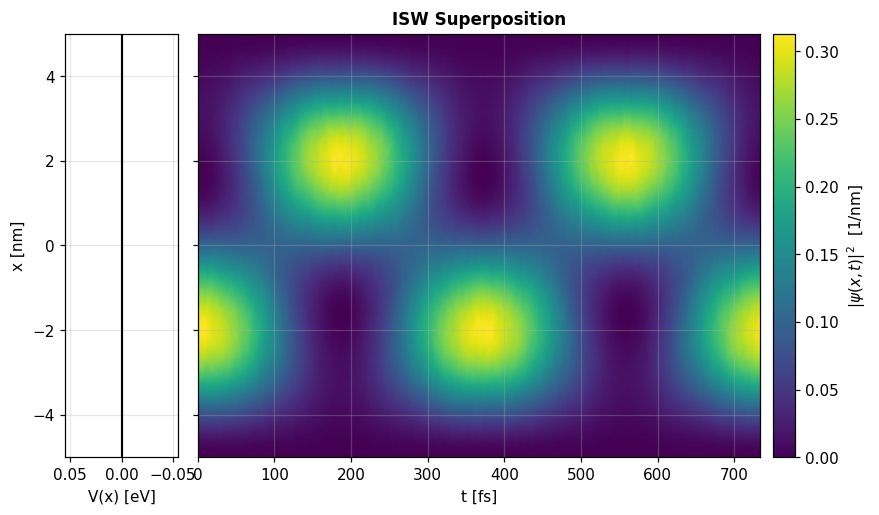

In [10]:
fig, ax = viz.spacetime_heatmap(
    res, V=V.V,
    title="ISW Superposition")
plt.show()

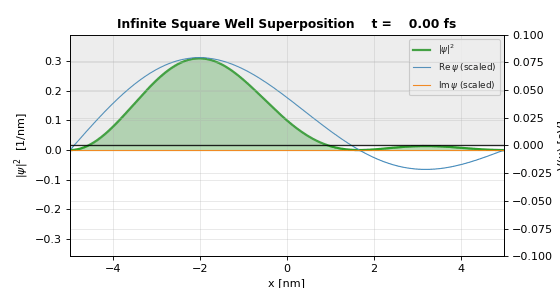

In [11]:
viz.make_gif(res, save_path=os.path.join(FIGDIR, "01_isw_beating.gif"),
             V=V.V, fps=20, title="Infinite Square Well Superposition")
show_gif("01_isw_beating.gif")

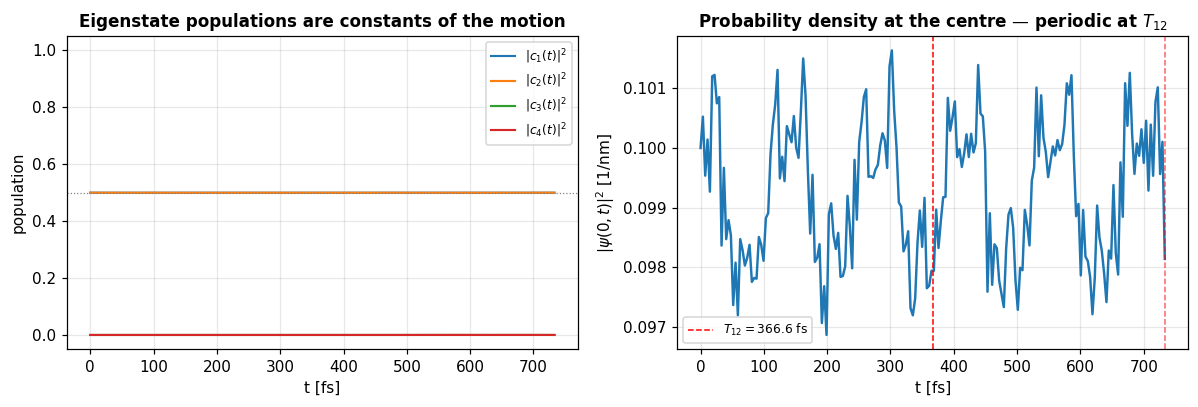

In [12]:
# --- diagnostics: eigenstate populations are exactly stationary ------
# Project psi(t) onto the analytic eigenbasis.  Because (phi_1+phi_2)/sqrt(2)
# contains *only* the n=1 and n=2 components, the populations |c_n(t)|^2
# for n=3,4 should be zero, and |c_1|^2 = |c_2|^2 = 1/2 for all t.
Cn = np.zeros((len(res.times), 4), dtype=complex)
for j, n in enumerate([1, 2, 3, 4]):
    phi_n = analytical.isw_eigenstate(n, g.x, -L/2, L/2)
    for i, psi in enumerate(res.psi):
        Cn[i, j] = observables.project_onto(psi, phi_n, g.dx)

fig, axes = plt.subplots(1, 2, figsize=(11, 3.8))
for j, n in enumerate([1, 2, 3, 4]):
    axes[0].plot(res.times/units.FS, np.abs(Cn[:, j])**2,
                 label=f"$|c_{n}(t)|^2$")
axes[0].axhline(0.5, color="0.5", lw=0.8, ls=":")
axes[0].set_xlabel("t [fs]"); axes[0].set_ylabel("population")
axes[0].set_title("Eigenstate populations are constants of the motion")
axes[0].legend(fontsize=8); axes[0].set_ylim(-0.05, 1.05)

rho_centre = np.abs(res.psi)**2 * g.dx
rho_centre = rho_centre[:, np.argmin(np.abs(g.x - 0.0))] / g.dx
axes[1].plot(res.times/units.FS, rho_centre*units.NM, lw=1.6)
axes[1].axvline(T12/units.FS, color="r", ls="--", lw=1.0,
                label=f"$T_{{12}} = {T12/units.FS:.1f}$ fs")
axes[1].axvline(2*T12/units.FS, color="r", ls="--", lw=1.0, alpha=0.6)
axes[1].set_xlabel("t [fs]"); axes[1].set_ylabel(r"$|\psi(0,t)|^2$ [1/nm]")
axes[1].set_title("Probability density at the centre — periodic at $T_{12}$")
axes[1].legend(fontsize=8)
fig.tight_layout(); plt.show()

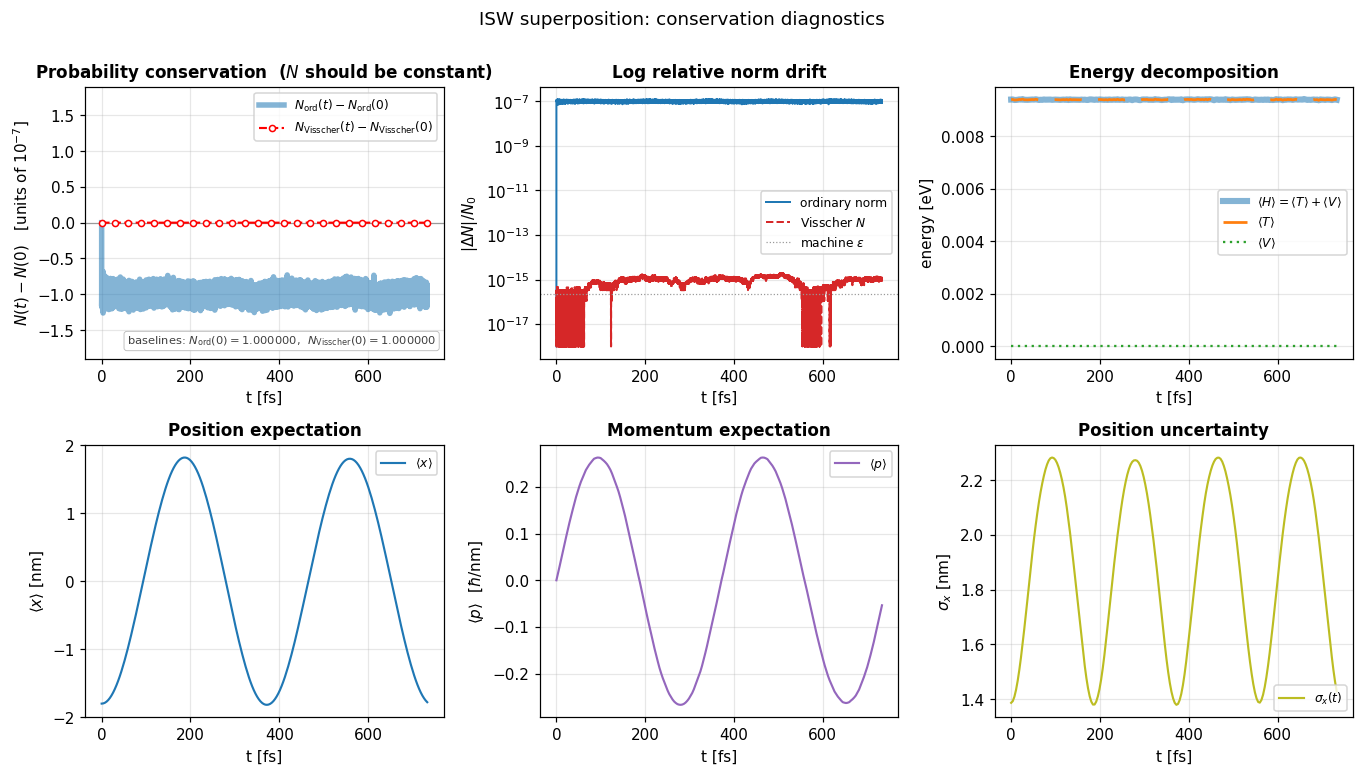

In [13]:
fig, _ = viz.plot_observables_panel(
    res, V_static=V.V,
    title="ISW superposition: conservation diagnostics")
plt.show()

Notice the energy decomposition: $\langle V\rangle = 0$ (the well is
flat-bottomed), so $\langle H\rangle = \langle T\rangle = (E_1+E_2)/2$
and is *exactly* constant.  The momentum $\langle p\rangle$
oscillates because the centre of probability sloshes back and forth.

## 3. Quantum harmonic oscillator

The harmonic oscillator $V(x) = \tfrac12 m\omega^2 x^2$ has discrete
eigenstates $\phi_n(x)$ with energies $E_n = \hbar\omega(n+\tfrac12)$.
We do **two** experiments here that together demonstrate quantum
behaviour:

* **(A)** A *stationary* eigenstate $\phi_n(x)$ has $|\psi(x,t)|^2 =
  |\phi_n(x)|^2$ independent of time — only the phase rotates at
  $\omega_n = E_n/\hbar$.  The space-time heatmap of $|\psi|^2$ is
  *uniform horizontal stripes*, while $\mathrm{Re}\,\psi(x,t)$
  oscillates at $\omega_n$.  This is the strongest possible test of
  the long-time stability of the solver.
* **(B)** A *coherent state* $|\alpha\rangle$ is a Gaussian wave
  packet that **does not spread** — it just rocks back and forth
  between $\pm x_{\rm cl}$ with the classical period $T = 2\pi/\omega$.
  This is the *quantum analogue* of classical SHM, and it exists
  only because the harmonic potential is special.

In [14]:
# --- (A) Stationary n=2 eigenstate: |psi|^2 is constant, Re psi oscillates --
omega = 2*np.pi * 3.7e13
sigma_ho = np.sqrt(units.HBAR/(2*units.M_E*omega))   # ground-state width
T_period = 2*np.pi/omega
print(f"hbar omega = {units.HBAR*omega/units.EV:.4f} eV,  "
      f"T = {T_period/units.FS:.2f} fs,  sigma_0 = {sigma_ho/units.NM:.3f} nm")

g = gridmod.make_grid_nm(-3, 3, 251)
V = potentials.harmonic(g, omega)

n_target = 2          # third-excited state has 3 lobes
phi_n = analytical.sho_eigenstate(n_target, g.x, omega)
phi_n = phi_n / np.sqrt(np.sum(np.abs(phi_n)**2)*g.dx)
psi0_ho_eigen = phi_n.astype(np.complex128)

dt = gridmod.visscher_dt_max(g, V_max=V.max_abs(g.x), safety=0.5)
lf = solvers.LeapfrogSolver(g, V, dt=dt, bc="hard")
n_steps = int(2*T_period/dt)            # two classical periods
res_eigen = lf.run(psi0_ho_eigen, n_steps=n_steps, n_save=180)
print(f"dt = {dt/units.FS:.4f} fs,  total time = {n_steps*dt/units.FS:.1f} fs "
      f"= {n_steps*dt/T_period:.2f} T")

hbar omega = 0.1530 eV,  T = 27.03 fs,  sigma_0 = 0.499 nm
dt = 0.0025 fs,  total time = 54.1 fs = 2.00 T


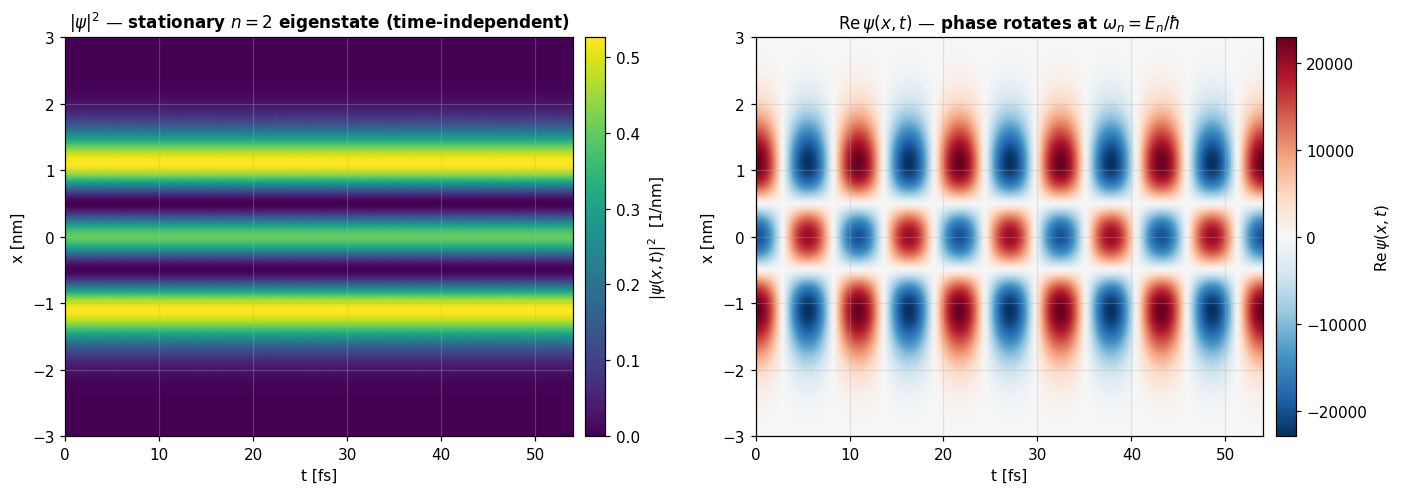

In [15]:
fig, axes = plt.subplots(1, 2, figsize=(13.0, 4.6))
viz.spacetime_heatmap(
    res_eigen, V=V.V, ax=axes[0],
    title=f"$|\\psi|^2$ — stationary $n={n_target}$ eigenstate (time-independent)",
    show_potential_panel=False)
viz.spacetime_heatmap(
    res_eigen, V=V.V, ax=axes[1], quantity="real",
    title=r"$\mathrm{Re}\,\psi(x,t)$ — phase rotates at $\omega_n=E_n/\hbar$",
    show_potential_panel=False)
fig.tight_layout(); plt.show()

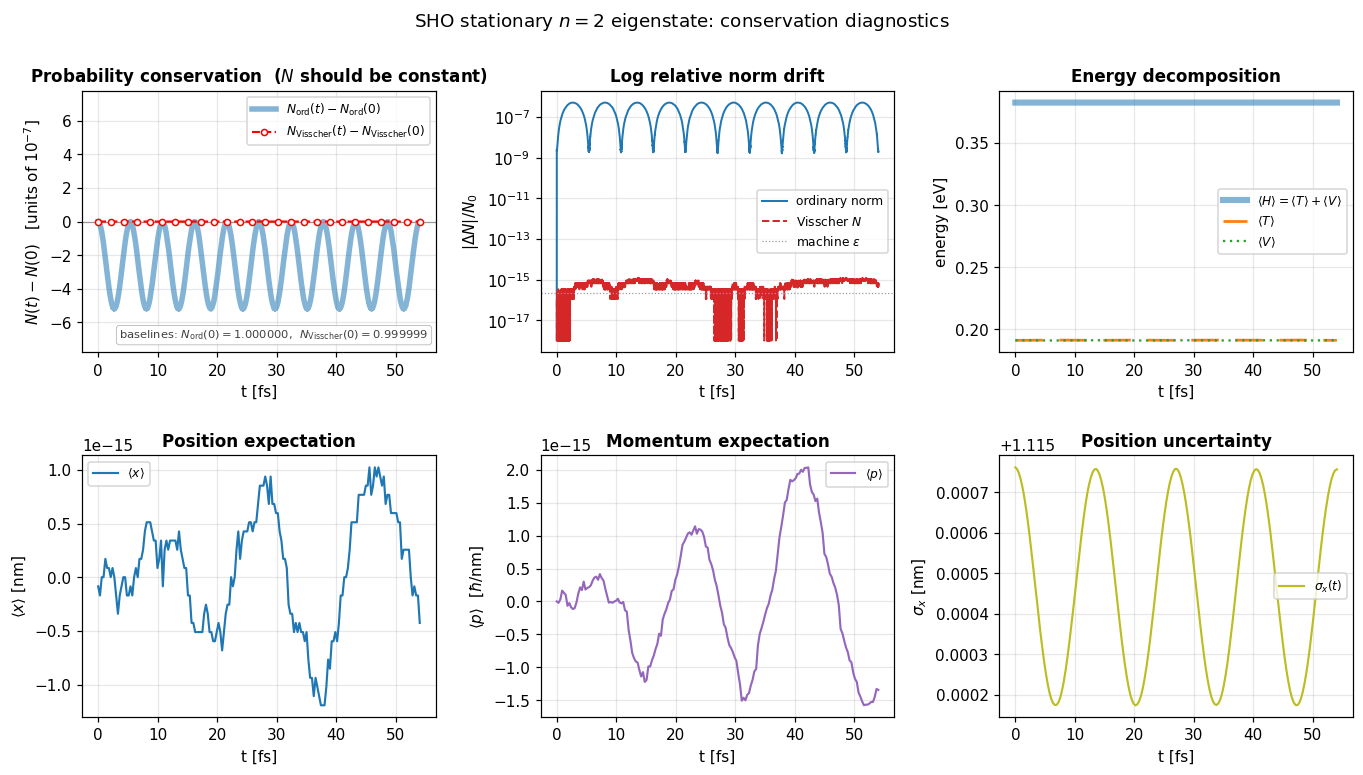

Expected E_2 = hbar*omega*(n + 1/2) = 0.3825 eV


In [16]:
fig, _ = viz.plot_observables_panel(
    res_eigen, V_static=V.V,
    title=f"SHO stationary $n={n_target}$ eigenstate: conservation diagnostics")
plt.show()
print(f"Expected E_{n_target} = hbar*omega*(n + 1/2) = "
      f"{(n_target+0.5)*units.HBAR*omega/units.EV:.4f} eV")

The first heatmap ($|\psi|^2$) has perfectly horizontal stripes:
the probability density of an energy eigenstate is *literally*
independent of time.  The second heatmap ($\mathrm{Re}\,\psi$)
oscillates uniformly in time at $\omega_2 = 2.5\,\hbar\omega/\hbar$
— the *phase* rotates but $|\psi|^2$ does not.  This is the defining
property of a stationary state and is exactly what a numerical solver
that conserves energy should produce.

### (B) Coherent state — quantum simple harmonic motion

In [17]:
# Coherent state |alpha> = D(alpha)|0> with alpha = 2.5 puts the centroid
# at x_cl = sqrt(2) * alpha * sigma_0 ~ 1.77 nm and gives
# <H> = hbar*omega*(|alpha|^2 + 1/2) ~ 6.5 * hbar omega.
alpha = 2.5
x_classical = np.sqrt(2)*alpha*sigma_ho
print(f"classical amplitude x_cl = {x_classical/units.NM:.3f} nm")

psi0_coh = gridmod.gaussian_packet(g, x0=x_classical, sigma=sigma_ho, k0=0.0)
n_steps = int(3*T_period/dt)             # three classical periods
res_coh = lf.run(psi0_coh, n_steps=n_steps, n_save=240)

classical amplitude x_cl = 1.764 nm


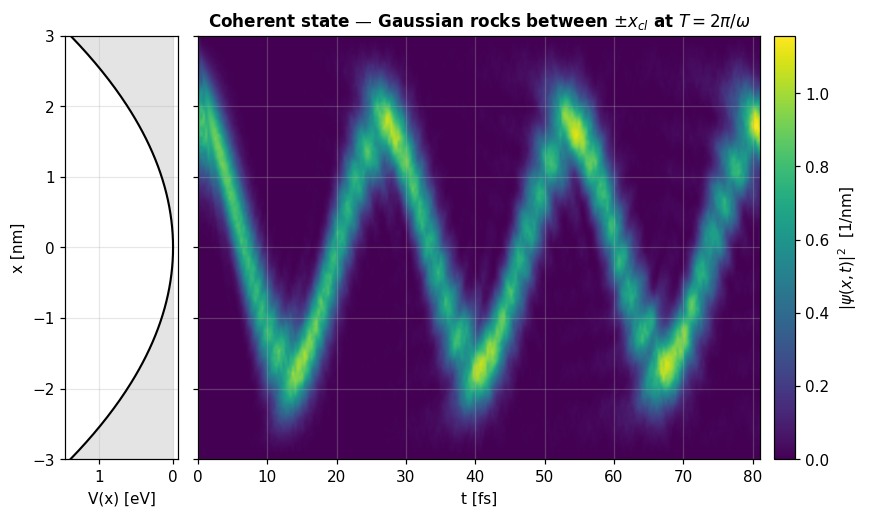

In [18]:
fig, ax = viz.spacetime_heatmap(
    res_coh, V=V.V,
    title="Coherent state — Gaussian rocks between $\\pm x_{cl}$ at $T = 2\\pi/\\omega$")
plt.show()

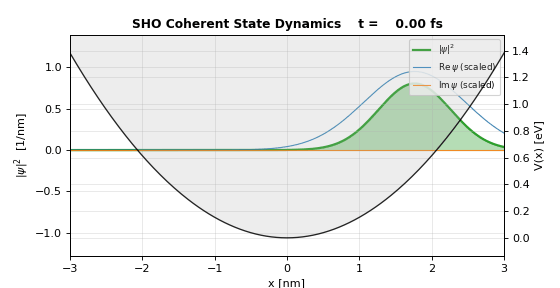

In [19]:
viz.make_gif(res_coh, save_path=os.path.join(FIGDIR, "01_coherent_state.gif"),
             V=V.V, fps=25, title="SHO Coherent State Dynamics")
show_gif("01_coherent_state.gif")

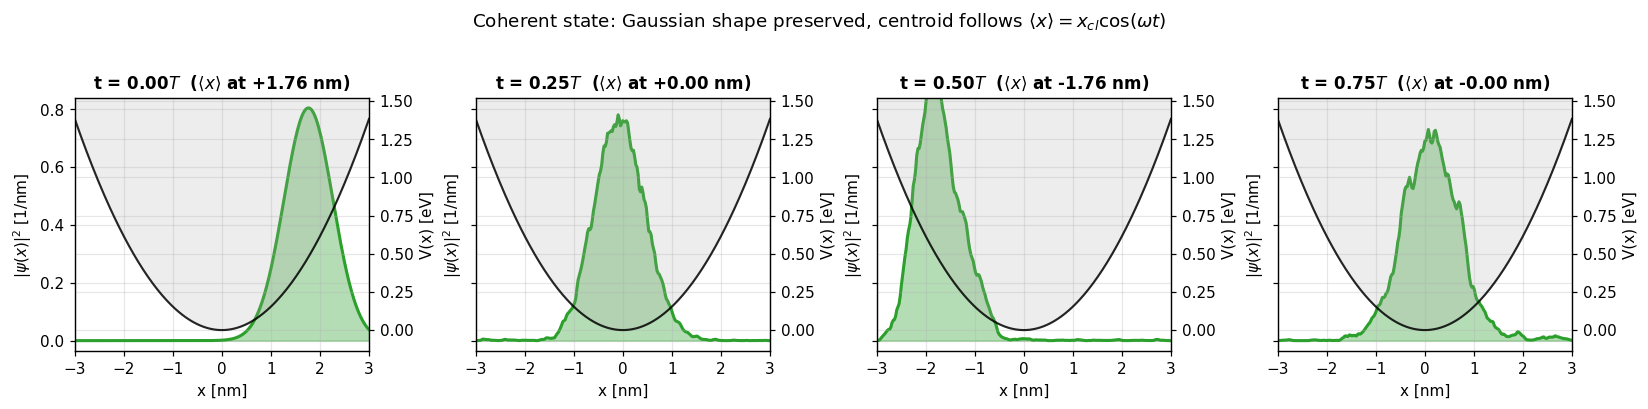

In [20]:
# Snapshots at t = 0, T/4, T/2, 3T/4 showing the swing
fig, axes = plt.subplots(1, 4, figsize=(15, 3.6), sharey=True)
for ax, frac in zip(axes, [0.0, 0.25, 0.5, 0.75]):
    ts = frac*T_period
    i = int(np.argmin(np.abs(res_coh.times - ts)))
    viz.plot_density_snapshot(
        res_coh.psi[i], g, V=V.V,
        title=f"t = {frac:.2f}$T$  ($\\langle x\\rangle$ at "
              f"{x_classical*np.cos(2*np.pi*frac)/units.NM:+.2f} nm)",
        ax=ax, show_components=False)
fig.suptitle("Coherent state: Gaussian shape preserved, centroid follows "
             "$\\langle x\\rangle = x_{cl}\\cos(\\omega t)$", y=1.02)
fig.tight_layout(); plt.show()

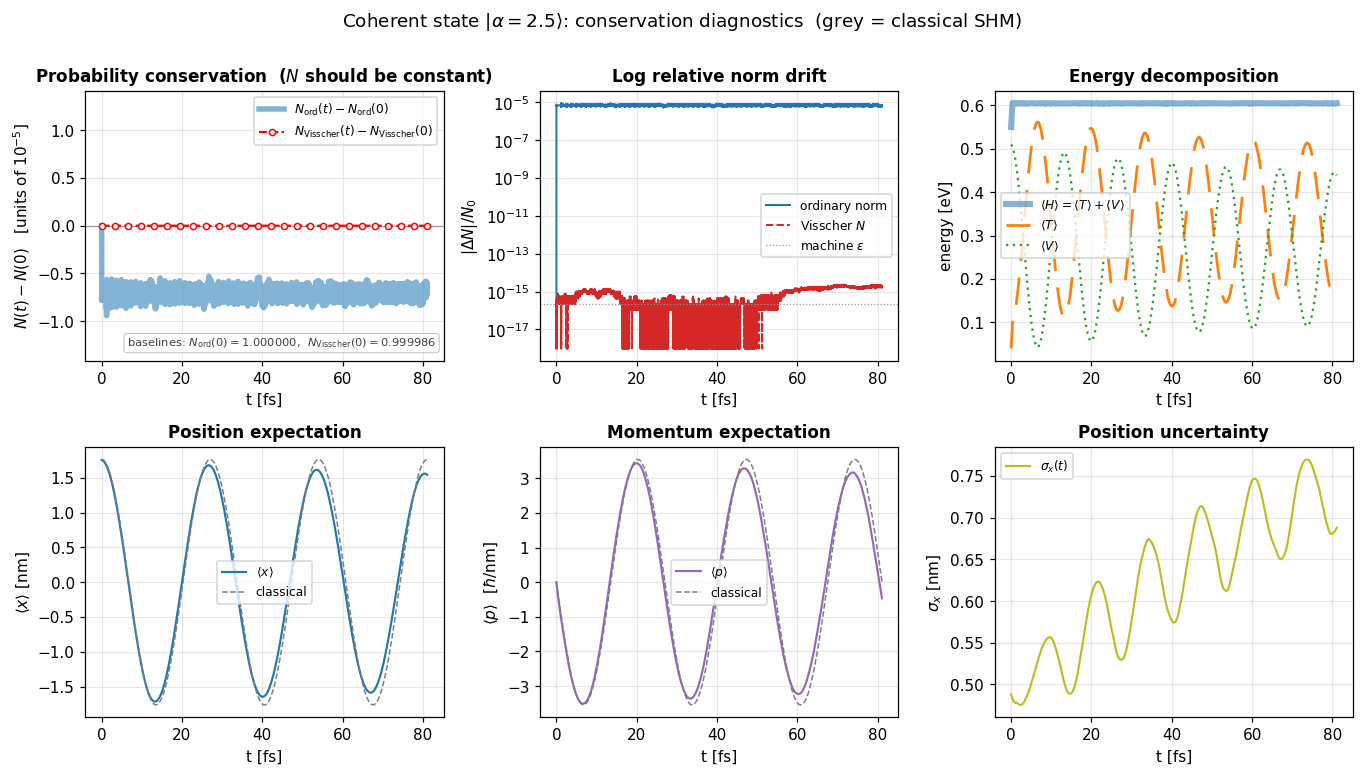

<E> for coherent state = hbar*omega*(|alpha|^2 + 1/2) = 1.0329 eV


In [21]:
classical_x = lambda t: x_classical * np.cos(omega*t)
classical_p = lambda t: -units.M_E * omega * x_classical * np.sin(omega*t)
fig, _ = viz.plot_observables_panel(
    res_coh, V_static=V.V,
    classical_x=classical_x, classical_p=classical_p,
    title=f"Coherent state $|\\alpha={alpha}\\rangle$: conservation diagnostics  "
          f"(grey = classical SHM)")
plt.show()
print(f"<E> for coherent state = hbar*omega*(|alpha|^2 + 1/2) = "
      f"{(alpha**2+0.5)*units.HBAR*omega/units.EV:.4f} eV")

The coherent-state diagnostics are textbook:

* $\langle x\rangle(t) = x_{\rm cl}\cos\omega t$ (classical SHM, grey
  dashed line on the figure),
* $\langle p\rangle(t) = -m\omega x_{\rm cl}\sin\omega t$ (classical
  momentum),
* $\sigma_x(t) = \sigma_0$ for all $t$  — the Gaussian shape is preserved,
* $\langle T\rangle$ and $\langle V\rangle$ each oscillate between
  0 and the maximum classical kinetic / potential energy, but their
  sum $\langle H\rangle = \hbar\omega(|\alpha|^2 + 1/2)$ is *constant*.

This is the strongest possible test of long-time stability — phase
errors that don't show up in a free packet would show up as a slow
"breathing" of $\sigma_x$ or as drift in $\langle H\rangle$.

## 4. Finite square well — bound-state leakage

The defining property of a *finite* well is that the bound-state
wavefunction extends into the classically forbidden region with an
exponential decay $\propto e^{-\kappa|x|}$, $\kappa=\sqrt{-2mE}/\hbar$
(with $E<0$ measured *outside* the well).  We solve the well
Hamiltonian by sparse direct diagonalisation and overlay the
analytic exponential reference.

In [22]:
# Finite square well: width 4 nm, depth 5 eV.  Convention here:
# V = 0 outside, V = -V_depth inside.  Bound-state energies are
# negative (E < 0) and lie above the well bottom.
V_depth = 5.0 * units.EV
a = 4.0 * units.NM
g = gridmod.make_grid_nm(-15, 15, 601)
V = potentials.finite_square_well(g, -a/2, a/2, V_depth)

from scipy.sparse import diags
from scipy.sparse.linalg import eigsh
Tk = units.HBAR**2/(2*units.M_E*g.dx**2)
H = diags([np.full(g.N-1, -Tk), 2*Tk + V.V, np.full(g.N-1, -Tk)],
          [-1, 0, 1], format="csr")
# bound states have E < 0; "smallest algebraic" gives the most-negative ones
E_levels, vecs = eigsh(H, k=4, which="SA")
order = np.argsort(E_levels)
E_levels = E_levels[order];  vecs = vecs[:, order]
print("Bound-state energies (E < 0 means bound):")
for n, E in enumerate(E_levels):
    if E < 0.0:
        print(f"  E_{n+1} = {E/units.EV:+.4f} eV    "
              f"=>  decay length 1/kappa = "
              f"{units.HBAR/np.sqrt(-2*units.M_E*E)/units.NM:.3f} nm")

Bound-state energies (E < 0 means bound):
  E_1 = -4.9785 eV    =>  decay length 1/kappa = 0.087 nm
  E_2 = -4.9140 eV    =>  decay length 1/kappa = 0.088 nm
  E_3 = -4.8067 eV    =>  decay length 1/kappa = 0.089 nm
  E_4 = -4.6568 eV    =>  decay length 1/kappa = 0.090 nm


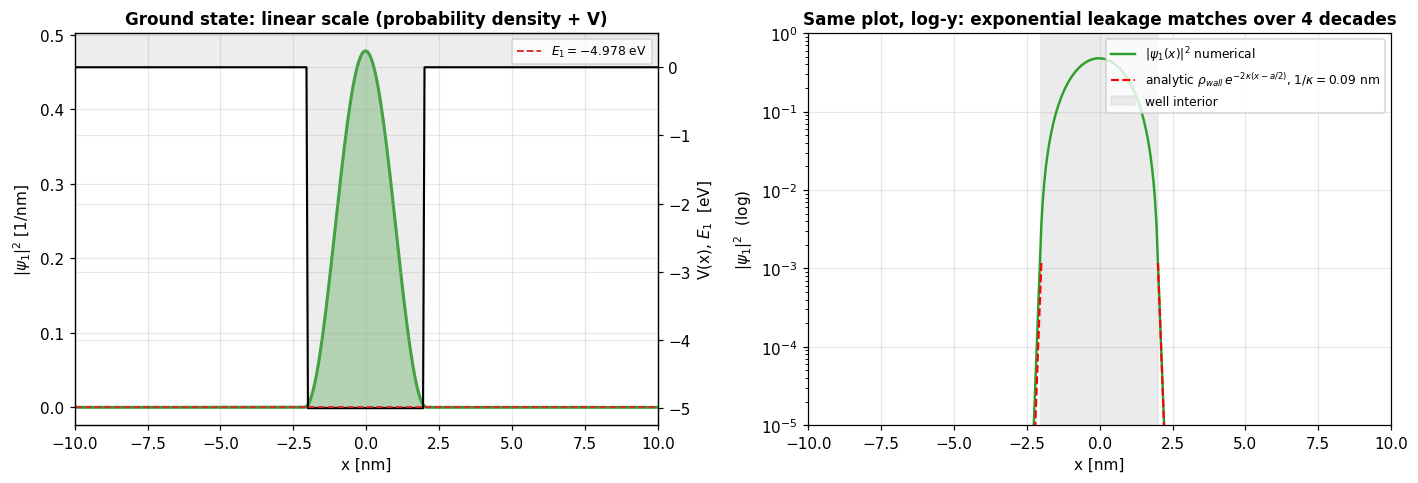

In [23]:
# --- Plot the ground-state |psi_1|^2 with the exponential decay reference ---
psi_g = vecs[:, 0]
psi_g = psi_g / np.sqrt(np.sum(np.abs(psi_g)**2)*g.dx)
psi_g = psi_g * np.sign(psi_g[g.N//2])           # canonical sign
E_g = E_levels[0]
kappa = np.sqrt(-2*units.M_E*E_g)/units.HBAR

fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))
# left: linear scale, V(x) overlay, classically forbidden region shaded
ax = axes[0]
rho_plot = np.abs(psi_g)**2 * units.NM
ax.fill_between(g.x/units.NM, 0.0, rho_plot, color="tab:green",
                alpha=0.35, label=r"$|\psi_1(x)|^2$")
ax.plot(g.x/units.NM, rho_plot, color="tab:green", lw=2.0)
ax_v = ax.twinx()
ax_v.fill_between(g.x/units.NM, V.V/units.EV, 1.0, color="0.65",
                  alpha=0.20, lw=0)
ax_v.plot(g.x/units.NM, V.V/units.EV, color="black", lw=1.4)
ax_v.axhline(E_g/units.EV, color="tab:red", ls="--", lw=1.2,
             label=f"$E_1 = {E_g/units.EV:.3f}$ eV")
ax_v.set_ylim(-V_depth/units.EV*1.05, 0.5)
ax_v.set_ylabel("V(x), $E_1$  [eV]")
ax_v.legend(loc="upper right", fontsize=8)
ax.set_xlabel("x [nm]"); ax.set_ylabel(r"$|\psi_1|^2$ [1/nm]")
ax.set_title("Ground state: linear scale (probability density + V)")
ax.set_xlim(-10, 10)

# right: log scale, exponential-decay reference outside the well
ax = axes[1]
rho_si = np.abs(psi_g)**2
rho_disp = rho_si * units.NM
ax.semilogy(g.x/units.NM, rho_disp, color="tab:green", lw=1.6,
            label=r"$|\psi_1(x)|^2$ numerical")
# analytic: rho(x) = rho_wall * exp(-2*kappa*(x - a/2)) outside
iwall = np.argmin(np.abs(g.x - a/2))
rho_wall = rho_disp[iwall]
x_out = g.x[g.x > a/2]
ax.semilogy(x_out/units.NM,
            rho_wall*np.exp(-2*kappa*(x_out - a/2)),
            "r--", lw=1.4,
            label=r"analytic $\rho_{wall}\,e^{-2\kappa(x-a/2)}$"
                   f", $1/\\kappa = {1/kappa/units.NM:.2f}$ nm")
ax.semilogy(-x_out/units.NM,
            rho_wall*np.exp(-2*kappa*(x_out - a/2)),
            "r--", lw=1.4)
ax.axvspan(-a/(2*units.NM), a/(2*units.NM), color="0.85", alpha=0.5,
           label="well interior")
ax.set_ylim(1e-5, 1)
ax.set_xlim(-10, 10)
ax.set_xlabel("x [nm]"); ax.set_ylabel(r"$|\psi_1|^2$  (log)")
ax.set_title("Same plot, log-y: exponential leakage matches over 4 decades")
ax.legend(fontsize=8, loc="upper right")
fig.tight_layout(); plt.show()

The numerical $|\psi_1|^2$ matches the predicted $e^{-2\kappa|x|}$
decay over $\sim 4$ orders of magnitude.  In notebook 02 we will
*send a wave packet at* a similar barrier and see this same
exponential as the basis of *quantum tunnelling*.